In [1]:
import nibabel
import numpy as np
import pickle
import matplotlib.pyplot as plt

In [2]:
import gzip

# mgz_file = 'data/video2024-10-24T09_58_36__223e__60035__masks_packed.mgz'
mgz_file = 'data/video2024-02-20T21_16_26__223e__59997__masks_packed.mgz'

with open(mgz_file, "rb") as f:
    print(f.read(2))   # b'\x1f\x8b' means gzip

with gzip.open(mgz_file, "rb") as f:
    print(f.read(8))   # MGH: starts with \x00\x00\x00\x01 (version 1)
                       # pickle: starts with \x80\x04 or \x80\x05 (protocol marker)

b'\x1f\x8b'
b'\x80\x05\x95\r\x01\x00\x00\x00'


In [3]:
import gzip, pickle, numpy as np

with gzip.open(mgz_file, "rb") as f:
    d = pickle.load(f)

def describe(x, name="root", depth=0, max_depth=4):
    pad = "  " * depth
    t = type(x).__name__
    if isinstance(x, np.ndarray):
        print(f"{pad}{name}: ndarray shape={x.shape} dtype={x.dtype} "
              f"min={x.min() if x.size else '-'} max={x.max() if x.size else '-'}")
    elif isinstance(x, dict):
        print(f"{pad}{name}: dict ({len(x)} keys)")
        if depth < max_depth:
            for k in list(x)[:8]:
                describe(x[k], repr(k), depth + 1, max_depth)
            if len(x) > 8:
                print(f"{pad}  ... {len(x) - 8} more keys")
    elif isinstance(x, (list, tuple)):
        print(f"{pad}{name}: {t} (len={len(x)})")
        if depth < max_depth and x:
            describe(x[0], "[0]", depth + 1, max_depth)
    else:
        s = repr(x)
        print(f"{pad}{name}: {t} = {s[:100]}{'...' if len(s) > 100 else ''}")

describe(d)

root: dict (7 keys)
  'video': str = 'video2024-02-20T21_16_26'
  'method': str = '223e'
  'frame_range': list (len=2)
    [0]: int = 0
  'n_frames': int = 59997
  'source': str = '/teamspace/studios/this_studio/zeus_tracking/outputs/savemasks_21_16_26/masks_packed'
  'fmt': str = 'header+per_frame_records'
  'record': str = '(frame:int, {oid:(shape,packbits)})'


In [4]:
import gzip, pickle, numpy as np

with gzip.open(mgz_file, "rb") as f:
    d = pickle.load(f)

def dump(x, name="root", depth=0):
    pad = "  " * depth
    if isinstance(x, np.ndarray):
        print(f"{pad}{name}: ndarray shape={x.shape} dtype={x.dtype}")
    elif isinstance(x, dict):
        print(f"{pad}{name}: dict ({len(x)} keys)")
        for k, v in x.items():          # no cap, no depth limit
            dump(v, repr(k), depth + 1)
    elif isinstance(x, (list, tuple)):
        print(f"{pad}{name}: {type(x).__name__} (len={len(x)})")
        for i, v in enumerate(x):
            dump(v, f"[{i}]", depth + 1)
    else:
        print(f"{pad}{name}: {type(x).__name__} = {x!r}")   # full repr

dump(d)

root: dict (7 keys)
  'video': str = 'video2024-02-20T21_16_26'
  'method': str = '223e'
  'frame_range': list (len=2)
    [0]: int = 0
    [1]: int = 59996
  'n_frames': int = 59997
  'source': str = '/teamspace/studios/this_studio/zeus_tracking/outputs/savemasks_21_16_26/masks_packed'
  'fmt': str = 'header+per_frame_records'
  'record': str = '(frame:int, {oid:(shape,packbits)})'


In [5]:
import gzip, pickle, numpy as np

path = mgz_file

def iter_masks(path):
    """Yields (frame_idx, {oid: bool_array}) per frame."""
    with gzip.open(path, "rb") as f:
        header = pickle.load(f)          # the 7-key dict you already dumped
        while True:
            try:
                frame, objs = pickle.load(f)
            except EOFError:
                return
            yield frame, {oid: unpack(shape, packed)
                          for oid, (shape, packed) in objs.items()}

def unpack(shape, packed):
    n = int(np.prod(shape))
    buf = np.frombuffer(packed, dtype=np.uint8) if isinstance(packed, (bytes, bytearray)) else packed
    return np.unpackbits(buf, count=n).reshape(shape).astype(bool)

In [6]:
for frame, objs in iter_masks(mgz_file):
    for oid, m in objs.items():
        print(frame, oid, m.shape, m.dtype, m.sum(), "px")
    break

0 0 (912, 912) bool 2873 px
0 1 (912, 912) bool 3612 px
0 2 (912, 912) bool 1143 px
0 3 (912, 912) bool 1463 px


In [15]:
import gzip, pickle, numpy as np

def unpack(shape, packed):
    n = int(np.prod(shape))
    buf = np.frombuffer(packed, dtype=np.uint8) if isinstance(packed, (bytes, bytearray)) else packed
    return np.unpackbits(buf, count=n).reshape(shape).astype(bool)


def iter_ranges(path, ranges, oids=None, unpack_masks=True):
    """
    Stream masks for the requested frame ranges.

    ranges : (start, end) or list of them. Inclusive on both ends.
    oids   : iterable of object IDs to keep, or None for all.
    unpack_masks : False keeps masks as (shape, packed_bytes) — 8x smaller.

    Yields (frame_idx, {oid: bool_array}) in file order.
    Frames present in a range but missing from the file are simply not yielded.
    """
    if ranges and isinstance(ranges[0], int):
        ranges = [ranges]
    ranges = sorted(tuple(r) for r in ranges)
    if not ranges:
        return
    last = max(end for _, end in ranges)
    want = set(oids) if oids is not None else None

    def in_range(fr):
        return any(s <= fr <= e for s, e in ranges)

    with gzip.open(path, "rb") as f:
        pickle.load(f)                       # discard header
        while True:
            try:
                frame, objs = pickle.load(f)
            except EOFError:
                return
            if frame > last:                 # records are ordered — nothing left to find
                return
            if not in_range(frame):
                continue
            if want is not None:
                objs = {o: v for o, v in objs.items() if o in want}
                if not objs:
                    continue
            if unpack_masks:
                objs = {o: unpack(*v) for o, v in objs.items()}
            yield frame, objs

# # collect into stacked arrays, one per object
# def collect(path, ranges, oids=None):
#     frames, per_oid = [], {}
#     for frame, objs in iter_ranges(path, ranges, oids):
#         frames.append(frame)
#         for o, m in objs.items():
#             per_oid.setdefault(o, []).append(m)
#     return frames, {o: np.stack(v) for o, v in per_oid.items()}
            
def collect(path, ranges, oids=None):
    """Returns (frames, masks) where masks has shape (n_fish, n_frames, H, W),
       first axis = the different fish (ordered by oid)."""
    frames, per_oid = [], {}
    for frame, objs in iter_ranges(path, ranges, oids):
        frames.append(frame)
        for o, m in objs.items():
            per_oid.setdefault(o, []).append(m)
    order = sorted(per_oid)                                   # consistent fish order
    masks = np.stack([np.stack(per_oid[o]) for o in order])  # (n_fish, n_frames, H, W)
    return frames, masks

frames, masks = collect(path, (0, 1000), oids=None)

In [18]:
print(masks.shape)
np.save(f'{mgz_file}_masks_first_1000_frames.npy', masks)

(4, 1001, 912, 912)


In [7]:
import gzip, pickle

with gzip.open(mgz_file, "rb") as f:
    obj = pickle.load(f)

print(obj.keys())
print(obj['video'])
print()

dict_keys(['video', 'method', 'frame_range', 'n_frames', 'source', 'mgz_sha256', 'reid_map_src_to_dst', 'reid_ref_video', 'reid_ref_method', 'reid_base_method', 'reid_note'])
video2024-10-24T09_58_36


In [3]:
path = "data/masks_packed.pkl"

with open("data/masks_packed.pkl", "rb") as f:
    obj = pickle.load(f)
    print(obj['mgz_sha256'])
    print(obj['video'])
    print(obj['source'])

print("type:", type(obj))

if isinstance(obj, dict):
    print("keys:", list(obj.keys())[:20])
    k = next(iter(obj))
    print("sample:", repr(k), "->", type(obj[k]))
elif isinstance(obj, (list, tuple)):
    print("len:", len(obj), "| first:", type(obj[0]), repr(obj[0])[:200])
else:
    print(repr(obj)[:300])

cc2d55155495d8fa2c8d1da3accff3b4ebf34a9f55a64168882bd98c7280aa2e
job_01kvtx1695v26g7bav5fzm54wd
axovera overflow derived
type: <class 'dict'>
keys: ['video', 'method', 'frame_range', 'n_frames', 'source', 'mgz_sha256']
sample: 'video' -> <class 'str'>


In [8]:
def unpack_mask(shape, packed):
    bits = np.unpackbits(packed)
    return bits[:shape[0]*shape[1]].reshape(shape).astype(bool)

def iter_frames(path):
    """Yield (frame_index, {oid: boolean_mask}) for every frame, one at a time."""
    with open(path, "rb") as f:
        pickle.load(f)                                   # skip the manifest
        while True:
            try:
                frame, objects = pickle.load(f)
            except EOFError:
                break
            yield frame, {oid: unpack_mask(shape, packed)
                          for oid, (shape, packed) in objects.items()}

In [77]:
def grab_frames(path, wanted):
    wanted = set(wanted); out = {}
    with open(path, "rb") as f:
        pickle.load(f)
        while wanted:
            try: frame, objects = pickle.load(f)
            except EOFError: break
            if frame in wanted:
                out[frame] = {oid: unpack_mask(s, p) for oid, (s, p) in objects.items()}
                wanted.discard(frame)
    return out

frames_interest = [0,600,800]
masks_by_frame = grab_frames(path, frames_interest)   # stops after the last one
print(masks_by_frame.keys())
print(masks_by_frame[800].keys())

dict_keys([0, 600, 800])
dict_keys([0, 1, 2, 3])


In [80]:
mask_example_3_frames = np.zeros((3,4,masks_by_frame[0][0].shape[0],masks_by_frame[0][0].shape[0]))
for frame in range(len(frames_interest)):
    for fish in range(4):
        mask_example_3_frames[frame,fish] = masks_by_frame[frames_interest[frame]][fish]

np.save('data/mask_example_3_frames.npy', mask_example_3_frames)

In [79]:
print(masks_by_frame[0][0].shape)

(912, 912)


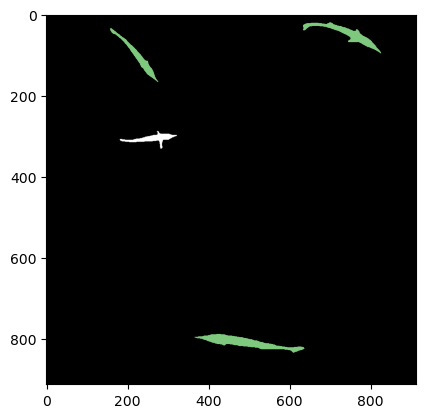

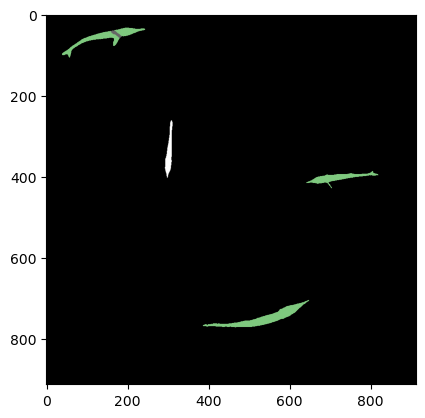

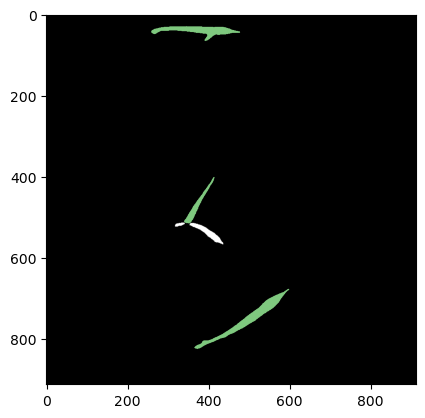

In [78]:
import numpy as np
import matplotlib.pyplot as plt

for frame in frames_interest:
    fig, ax = plt.subplots()
    ax.imshow(masks_by_frame[frame][0], cmap='gray')

    # Hide everything that's 0 (background); only nonzero labels remain visible
    for i in [1,2,3]:
        masked = np.ma.masked_where(masks_by_frame[frame][i] == 0, masks_by_frame[0][1])
        ax.imshow(masked, cmap='Accent', alpha=1)

    plt.show()

dict_keys([0, 1, 2, 3])


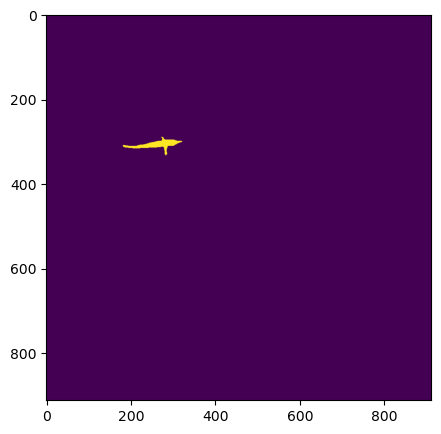

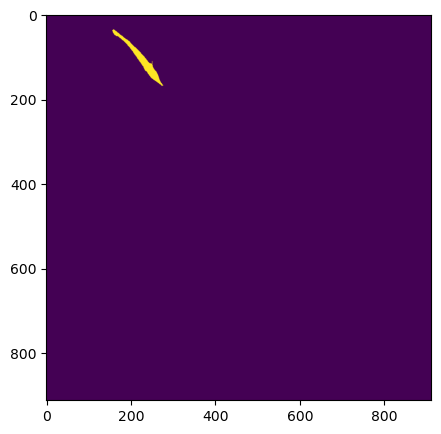

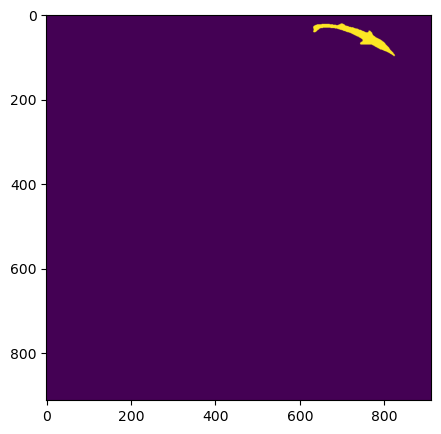

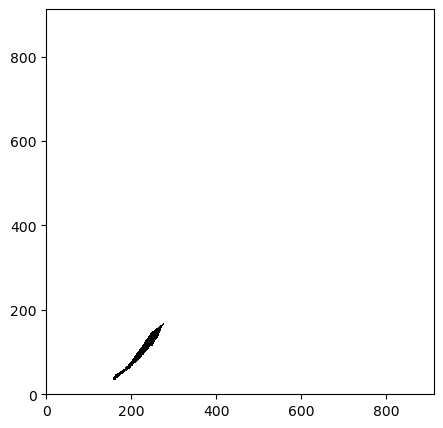

In [41]:
# probably mask of first fish on first frame
print(masks_by_frame[0].keys())

def prep_layer(bool_array):
    return np.where(bool_array, 1.0, np.nan)


fig, axes = plt.subplots(figsize=(5,5))
axes.imshow(masks_by_frame[0][0])

fig, axes = plt.subplots(figsize=(5,5))
axes.imshow(masks_by_frame[0][1])

fig, axes = plt.subplots(figsize=(5,5))
axes.imshow(masks_by_frame[0][2])

fig, axes = plt.subplots(figsize=(5,5))
axes.pcolormesh(prep_layer(masks_by_frame[0][1]), cmap='gray', vmin=1.0, vmax=1.0)





In [12]:
oid = 0                                # the fish you care about
frames, cx, cy = [], [], []
for frame, masks in iter_frames(path):
    m = masks.get(oid)
    if m is not None and m.any():
        ys, xs = np.where(m)
        frames.append(frame); cx.append(xs.mean()); cy.append(ys.mean())

frames, cx, cy = map(np.array, (frames, cx, cy))
print(f"fish {oid}: {len(frames)} frames present, x {cx.min():.0f}–{cx.max():.0f}, y {cy.min():.0f}–{cy.max():.0f}")

fish 0: 54975 frames present, x 27–863, y 27–849


In [15]:
print(frames)
print(cx.shape)

[    0     1     2 ... 60033 60034 60035]
(54975,)


# Other attempts

In [3]:
# try this first (v7 and earlier)
from scipy.io import loadmat
d = loadmat("data/EODdata_2024-10-23T15_18_28.mat", squeeze_me=True)
print([k for k in d if not k.startswith("__")])

# if that errors with "Unknown mat file type / v7.3", it's HDF5:
import h5py
with h5py.File("data/EODdata_2024-10-23T15_18_28.mat", "r") as f:
    f.visit(print)        # prints the variable tree

NotImplementedError: Please use HDF reader for matlab v7.3 files, e.g. h5py

In [4]:
import h5py

def show(name, obj):
    if isinstance(obj, h5py.Dataset) and not name.startswith("#"):
        print(f"{name:50s} shape={obj.shape} dtype={obj.dtype}")

with h5py.File("data/EODdata_2024-10-23T15_18_28.mat", "r") as f:
    print("top-level:", list(f.keys()))
    f.visititems(show)

with h5py.File("data/EODdata_2024-10-23T15_18_28.mat", "r") as f:
    ot = np.array(f["Objtime"]).ravel()
    st = np.array(f["Synctime"]).ravel()
    raw = f["NewRaw"]

    print("Objtime:", ot, "| diff:", float(ot[1]-ot[0]))
    print("Synctime: n=%d span=%.4g diffs(mean/med)=%.4g/%.4g"
          % (st.size, st.max()-st.min(), np.diff(st).mean(), np.median(np.diff(st))))

    blk = np.array(raw[:200_000, :], float)        # one window, all channels
    print("first rows:\n", blk[:3])
    for c in range(raw.shape[1]):
        print(f"ch{c+1}: std={blk[:,c].std():.4g} max|.|={np.abs(blk[:,c]).max():.4g}")

top-level: ['NewRaw', 'Objtime', 'Synctime']
NewRaw                                             shape=(60000000, 10) dtype=float64
Objtime                                            shape=(2,) dtype=uint64
Synctime                                           shape=(159, 1) dtype=float64
Objtime: [1 0] | diff: 1.8446744073709552e+19
Synctime: n=159 span=1186 diffs(mean/med)=7.507/7.556
first rows:
 [[nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan]]
ch1: std=nan max|.|=nan
ch2: std=nan max|.|=nan
ch3: std=nan max|.|=nan
ch4: std=nan max|.|=nan
ch5: std=nan max|.|=nan
ch6: std=nan max|.|=nan
ch7: std=nan max|.|=nan
ch8: std=nan max|.|=nan
ch9: std=nan max|.|=nan
ch10: std=nan max|.|=nan


/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_27542/747495128.py:16: RuntimeWarning: overflow encountered in scalar subtract
  print("Objtime:", ot, "| diff:", float(ot[1]-ot[0]))


In [5]:
import nibabel

In [8]:
import nibabel as nib
import numpy as np

img = nib.load("data/video2024-02-20T21_16_26__223e__0-59996.mgz")          # MGHImage
data = img.get_fdata()              # numpy array of voxel values

print("shape:      ", data.shape)
print("dtype:      ", img.get_data_dtype())
print("voxel sizes:", img.header.get_zooms())
print("value range:", float(np.nanmin(data)), "to", float(np.nanmax(data)))
print("unique vals:", np.unique(data)[:20], "..." if data.size else "")   # handy if it's a label/segmentation
print("\naffine (voxel -> world):\n", np.round(img.affine, 3))

KeyError: 1872006168

In [12]:
with open("data/video2024-02-20T21_16_26__223e__0-59996.mgz", "rb") as f:
    head = f.read(200)
print(len(head), head[:60])
import os; print("size:", os.path.getsize("data/video2024-02-20T21_16_26__223e__0-59996.mgz"), "bytes")

200 b'\x1f\x8b\x08\x08\xef|"j\x00\xffvideo2024-02-20T21_16_26__223e__0-59996__masks_pac'
size: 110159777 bytes


In [13]:
import gzip, numpy as np

with gzip.open("data/video2024-02-20T21_16_26__223e__0-59996.mgz", "rb") as f:     # gzip, despite the .mgz name
    arr = np.load(f, allow_pickle=True)    # it was a .npy inside

print(type(arr), getattr(arr, "shape", None), getattr(arr, "dtype", None))

<class 'dict'> None None


In [17]:
for k in arr.keys():
    print(k)
    print(arr[k])

video
video2024-02-20T21_16_26
method
223e
frame_range
[0, 59996]
n_frames
59997
source
/teamspace/studios/this_studio/zeus_tracking/outputs/savemasks_21_16_26/masks_packed
fmt
header+per_frame_records
record
(frame:int, {oid:(shape,packbits)})


In [20]:
import numpy as np, gzip

with gzip.open("data/video2024-02-20T21_16_26__223e__0-59996.mgz", "rb") as f:
    arr = np.load(f, allow_pickle=True)

obj = arr.item() if isinstance(arr, np.ndarray) and arr.dtype == object and arr.ndim == 0 else arr
print(type(obj))
if isinstance(obj, dict):
    print("keys:", list(obj.keys()))           # e.g. 'header', 'records'/'frames'
else:
    print("len:", len(obj), "| first item:", type(obj[0]))


def unpack_mask(shape, packed):
    """packbits -> 2D boolean mask."""
    flat = np.unpackbits(np.frombuffer(packed, dtype=np.uint8))
    return flat[:int(np.prod(shape))].reshape(shape).astype(bool)

# adjust `records` to match what the print above showed (obj['records'], obj['frames'], or obj[1:])
records = obj["record"] if isinstance(obj, dict) else obj[1:]

frame, objects = records[0]                      # (frame_index, {oid: (shape, packbits)})
print("frame", frame, "| object ids:", list(objects.keys()))

for oid, (shape, packed) in objects.items():
    mask = unpack_mask(shape, packed)
    print(f"  oid {oid}: mask {mask.shape}, {mask.sum()} pixels set")

<class 'dict'>
keys: ['video', 'method', 'frame_range', 'n_frames', 'source', 'fmt', 'record']


ValueError: not enough values to unpack (expected 2, got 1)

In [21]:
import gzip, numpy as np

records = []
with gzip.open("data/video2024-02-20T21_16_26__223e__0-59996.mgz", "rb") as f:
    header = np.load(f, allow_pickle=True).item()
    print("header:", header["n_frames"], "frames expected")
    while True:
        try:
            records.append(np.load(f, allow_pickle=True))   # one record per call
        except (EOFError, ValueError, OSError):
            break
print("records read:", len(records))
print("first:", type(records[0]), records[0] if len(records) else None)

AttributeError: 'dict' object has no attribute 'item'

In [23]:
import gzip, numpy as np

records = []
with gzip.open("data/video2024-02-20T21_16_26__223e__0-59996.mgz", "rb") as f:
    header = np.load(f, allow_pickle=True)            # <-- no .item()
    if isinstance(header, np.ndarray):                # be tolerant either way
        header = header.item()
    print("header:", header["n_frames"], "frames expected")
    while True:
        try:
            records.append(np.load(f, allow_pickle=True))
        except (EOFError, ValueError, OSError, pickle_err if (pickle_err:=__import__("pickle").UnpicklingError) else Exception):
            break

print("records read:", len(records))
if records:
    print("first record type:", type(records[0]))
    print("first record:", records[0])

header: 59997 frames expected


KeyboardInterrupt: 

In [5]:
import gzip, numpy as np, pickle

with gzip.open("data/video2024-02-20T21_16_26__223e__0-59996.mgz", "rb") as f:
    header = np.load(f, allow_pickle=True)          # consumes exactly the header
    print("header keys:", list(header.keys()))
    rest = f.read()                                  # everything after the header
print("bytes remaining:", len(rest))
print("first 16 bytes:", rest[:16])

header keys: ['video', 'method', 'frame_range', 'n_frames', 'source', 'fmt', 'record']


KeyboardInterrupt: 

cc2d55155495d8fa2c8d1da3accff3b4ebf34a9f55a64168882bd98c7280aa2e
type: <class 'dict'>
keys: ['video', 'method', 'frame_range', 'n_frames', 'source', 'mgz_sha256']
sample: 'video' -> <class 'str'>


NameError: name 'unpack_mask' is not defined